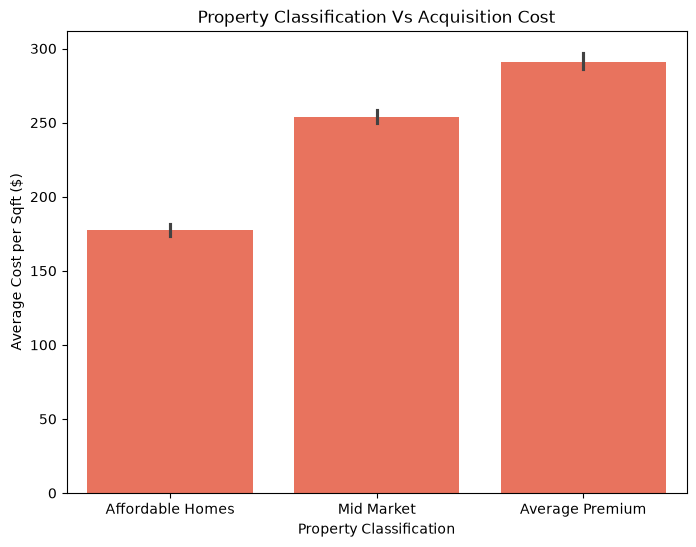

| city         |   Affordable Homes |   Mid Market |   Average Premium |
|:-------------|-------------------:|-------------:|------------------:|
| Seattle      |                193 |          745 |               402 |
| Kent         |                110 |           68 |                 5 |
| Auburn       |                110 |           57 |                 6 |
| Federal Way  |                100 |           37 |                 8 |
| Renton       |                 90 |          171 |                24 |
| Des Moines   |                 40 |           14 |                 2 |
| Burien       |                 39 |           23 |                 6 |
| Maple Valley |                 35 |           56 |                 4 |
| Covington    |                 34 |            7 |                 0 |
| Shoreline    |                 33 |           77 |                 6 |
|    | core_segment     |   count_of_houses |   avg_price_per_sqft |   avg_total_price |
|---:|:-----------------|----------

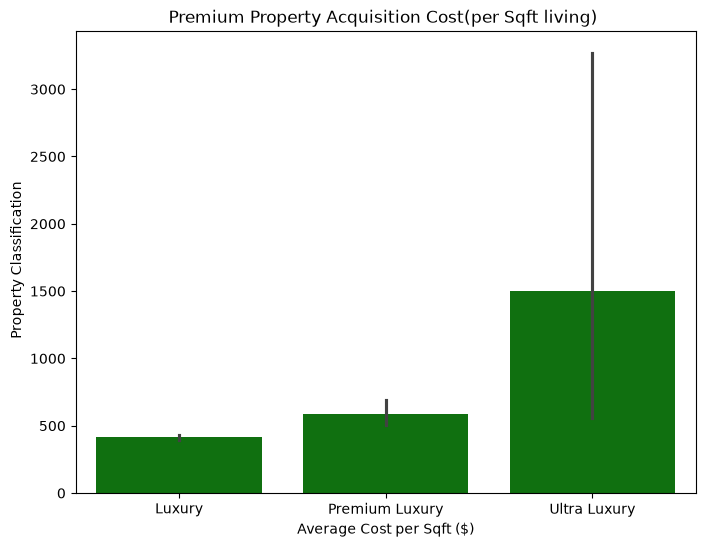

| city          |   Luxury |   Premium Luxury |   Ultra Luxury |
|:--------------|---------:|-----------------:|---------------:|
| Seattle       |       85 |               14 |              1 |
| Bellevue      |       41 |                6 |              2 |
| Mercer Island |       26 |                5 |              1 |
| Kirkland      |        9 |                2 |              0 |
| Redmond       |        7 |                1 |              0 |
| Medina        |        4 |                5 |              1 |
| Clyde Hill    |        4 |                1 |              1 |
| Sammamish     |        4 |                1 |              0 |
| Woodinville   |        3 |                0 |              0 |
| Fall City     |        2 |                0 |              0 |
|    | premium_segment   |   count_of_houses |   avg_price_per_sqft |   avg_total_price |
|---:|:------------------|------------------:|---------------------:|------------------:|
|  0 | Luxury            |              

In [25]:
import pandas as pd
import numpy as np
import seaborn as sns

data = pd.read_csv("house price.csv")
db=data.copy()
#db.info()
db.isnull().sum()
db.duplicated().sum()
db.head(5)
db['city'].unique()## total number of city is 44 
db[db['price'] == db['price'].max()] # kent is the city with the most expensive house 
db[db['price'] == db['price'].min() ]
db = db[db['price']>0]
db[db['price'] == db['price'].min() ] # the cheapest house is in Tukwila
avg_price= db['price'].mean()
Q1= db['price'].quantile(0.25)
Q3= db['price'].quantile(0.75)
IQR=Q3-Q1
upper=Q3+1.5*IQR
lower=Q1-1.5*IQR
core_market= db[(db['price']>=lower)&(db['price']<=upper)].copy()
premium=db[db['price']>upper].copy()
premium[['price', 'city']].sort_values(by='price',ascending=False).head(15) 
core_market[['price', 'city']].sort_values(by='price',ascending=False).head(15)
#core market city by price by binning the price
core_market['price_per_sqft_liv']= core_market['price']/core_market['sqft_living']
premium['price_per_sqft_liv']= premium['price']/premium['sqft_living']
premium['price'].mean()# the mean for core_market is (443863.13888158294) and premium is (1289154.02149836)
core_market['core_segment']=pd.cut(core_market['price'],
    bins=[0,300000,550000,824000],
    labels=['Affordable Homes', 'Mid Market','Average Premium'])
premium['premium_segment']=pd.cut(premium['price'],
    bins=[0,2000000,3500000,13000000],
    labels=['Luxury', 'Premium Luxury','Ultra Luxury'])
import matplotlib.pyplot as plt
##Core Market Segment
fig,ax= plt.subplots(figsize=(8,6))
sns.barplot(data=core_market,x = 'core_segment',y='price_per_sqft_liv',color='tomato')
plt.title('Property Classification Vs Acquisition Cost')
plt.ylabel('Average Cost per Sqft ($)')
plt.xlabel(' Property Classification ')
plt.show()
core_distribution = core_market.pivot_table(
    values='price',
    index='city',
    columns='core_segment',
    aggfunc='count',
    fill_value=0)

core_distribution_sorted = core_distribution.sort_values(
    by=['Affordable Homes', 'Mid Market','Average Premium'],
    ascending=False)

print(core_distribution_sorted.head(10).to_markdown()) # to show distribution of houses

core_Market_summary = core_market.groupby('core_segment').agg(
    count_of_houses=('price', 'size'),
    avg_price_per_sqft=('price_per_sqft_liv', 'mean'),
    avg_total_price=('price', 'mean')).reset_index()

print(core_Market_summary.to_markdown())

fig,ax= plt.subplots(figsize=(8,6))
sns.barplot(data=premium,x = 'premium_segment',y='price_per_sqft_liv',color='green')
plt.title('Premium Property Acquisition Cost(per Sqft living) ')
plt.xlabel('Average Cost per Sqft ($)')
plt.ylabel(' Property Classification')
plt.show()

premium_distribution = premium.pivot_table(
    values='price',
    index='city',
    columns='premium_segment',
    aggfunc='count',
    fill_value=0)

premium_distribution_sorted = premium_distribution.sort_values(
    by=['Luxury', 'Premium Luxury','Ultra Luxury'],
    ascending=False)

print(premium_distribution_sorted.head(10).to_markdown())

premium_Market_summary = premium.groupby('premium_segment').agg(
    count_of_houses=('price', 'size'),
    avg_price_per_sqft=('price_per_sqft_liv', 'mean'),
    avg_total_price=('price', 'mean')).reset_index()

print(premium_Market_summary.to_markdown())




